<style>
    #top {
        display: grid;
        grid-template-columns: auto auto auto
    }

    #top a {
        padding: 10px;
        background-color: blue;
        color: white;
        text-decoration: none
    }

    #top a:first-child {
        justify-self: start
    }

    #top a:last-child {
        justify-self: end
    }

    #top a:hover {
        background-color: darkblue
    }
</style>

<div id="top">
    <a href="../notebook/2_exploratory-data-analysis.ipynb">Previous</a>
    <h2 style="margin: 0; text-align: center;">Section 3 | Predictive Modeling</h2>
    <a href="../notebook/4_project-summary.ipynb">Next</a>
</div>

In [1]:
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from notebook_helpers import (
    ID_AUTO_MPG,
    INVALID_COLUMN,
    NOTEBOOK_DIR,
    RARE_COLUMN,
    RARE_VALUES,
    SEED,
    DropValues,
    data_cleaned_etl,
    data_inspect,
    data_raw_etl,
    inspect_dimensionality,
    match_transformer,
    random_number_generator,
)
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import PredictionErrorDisplay, median_absolute_error
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    LearningCurveDisplay,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline

### Model Pipeline

*To build a composite estimator, transformers are usually combined with other transformers or with predictors. There is often a fixed sequence of steps in processing the data—in this case, the examples are data ETL, cleaning inconsistencies, input splitting, and estimating output values.*

In [2]:
def feature_target_split(dataset, random_state, column_target="mpg"):
    """Split dataset into training and testing features and targets.

    Args:
        dataset (pd.DataFrame): Dataset containing the features and target.
        random_state: Seed or random number generator for reproducible splitting.
        column_target (str): Name of the target column.

    Returns:
        tuple: Training features, testing features, training target, and testing target.
    """
    features = dataset.drop(columns=column_target)
    target = dataset[column_target]
    return train_test_split(features, target, random_state=random_state)

*In machine learning:*
* *Features are the input variables (independent variables) used to make predictions, while*
* *The target is the variable to be predicted or understood (dependent variable).*
* *Together, they form the basis for supervised learning, where features map to a target value. Features are selected for relevance, and the target is the goal.*

In [3]:
# split features and target to random train and test subsets
data_cleaned = data_cleaned_etl()
rng = random_number_generator(SEED)
X_train, X_test, y_train, y_test = feature_target_split(data_cleaned, rng)

# perform dimensionality analysis of train-test subsets
inspect_dimensionality(data_cleaned, X_train, X_test)

,row_n,row_ratio,column
dataset,392,1.00,8
train,294,0.75,7
test,98,0.25,7


The split process above is roughly similar to the one performed in [Section 2: Train-Test Split](#train-test-split), with a few differences:
* `feature_target_split` divides `data` into 2 pairs: `X_train - X_test` and `y_train - y_test`.
* The overall data split proportion remains the same, but because the target variable `mpg` is also separated into `y_train` and `y_test`, the number of columns in `train` and `test`—that is, `X_train` and `X_test`—is reduced by 1 variable.

This function is integrated together with the preprocessors defined earlier into the following [pipeline](https://scikit-learn.org/stable/modules/compose.html) building process:

In [4]:
def modeling_pipeline(
    dataset_id,
    max_depth,
    l2_regularization,
    max_features,
    scoring,
    random_state
):
    """Build the preprocessing and estimator pipelines for the dataset."""
    match = match_transformer(INVALID_COLUMN)
    drop_values = DropValues(RARE_COLUMN, RARE_VALUES)
    preprocessing_pipeline = make_pipeline(match, drop_values)

    data = data_raw_etl(dataset_id)
    data_cleaned = preprocessing_pipeline.fit_transform(data)
    train_features, test_features, train_target, test_target = feature_target_split(
        data_cleaned, random_state
    )

    regressor = HistGradientBoostingRegressor(
        loss="absolute_error",
        max_depth=max_depth,
        l2_regularization=l2_regularization,
        max_features=max_features,
        early_stopping=True,
        scoring=scoring,
        random_state=random_state
    )

    pipeline = {
        "preprocessing": preprocessing_pipeline,
        "estimator": regressor
    }
    dataset = {
        "train": (train_features, train_target),
        "test": (test_features, test_target)
    }

    return pipeline, dataset

This model, [`HistGradientBoostingRegressor`](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), was selected based on the following considerations:
* As a new implementation of [Gradient-boosted Trees](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting)—which combine the predictions of several decision trees as their base estimators—, this particular model requires [little](https://scikit-learn.org/stable/modules/tree.html) data preparation:
    * It bypasses the need for data normalization by considering that decision trees use monotonic, [if-then-else](https://scikit-learn.org/stable/modules/tree.html) threshold rules to build the model.
    * `HistGradientBoostingRegressor` has [native support for categorical features](https://scikit-learn.org/stable/modules/ensemble.html#categorical-features-support), which is often better than relying on one-hot and/or ordinal encoding commonly used to convert such features into numerical representations for machine learning models.
    * This model also has [built-in support for missing values](https://scikit-learn.org/stable/modules/ensemble.html#missing-values-support), further reducing preprocessing complexity as shown in the display below.
* More importantly, this [non-parametric model](https://en.wikipedia.org/wiki/Nonparametric_statistics#Nonparametric_models) does not specify or assume the functional form of the model a priori—as was done in [Section 2: Linear Model Assumptions](#linear-model-assumptions)—but instead seeks an estimate as close as possible to the observed data points.

After the appropriate model is selected, the next step is to set the configurable [hyperparameters](https://en.wikipedia.org/wiki/Hyperparameter_(machine_learning)) inside the model:
* For the purpose of [selecting an appropriate loss function](https://en.wikipedia.org/wiki/Loss_function#Selecting_a_loss_function), a robust statistical method—in which the loss parameter is specified as [`absolute_error`](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting-loss)—is implemented to produce statistical results that are not unduly affected by heavy-tailed distributions as demonstrated in [Section 2: Linear Model Assumptions](#linear-model-assumptions).
* [Early stopping](https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_early_stopping.html) is a technique in gradient boosting to find the optimal number of iterations (`max_iter` in `HistGradientBoostingRegressor`) required to build a model that generalizes well to unseen data and avoids [overfitting](https://en.wikipedia.org/wiki/Overfitting).
    * *Enabling `early_stopping` also requires the `scoring` parameter to be set. The initial model is given by the [median](https://scikit-learn.org/stable/modules/ensemble.html#loss-functions) of the target values, hence the corresponding `neg_median_absolute_error` scoring string name is used.*
    * *The scoring object follows the [convention](https://scikit-learn.org/stable/modules/model_evaluation.html#string-name-scorers) that higher return values are better than lower return values. Thus the metric is available with the `neg_` prefix, which returns negated values of the error.*
* As for the tunable hyperparameters, namely `learning_rate`, `max_depth`, and `min_samples_leaf`, the values of these parameters use the default values first (*implemented below*) before being optimized in the next section.

In [5]:
# define tunable hyperparameters for modeling pipeline
max_depth = None
l2_regularization = 0
max_features = 1.0
scoring = "neg_median_absolute_error"

# execute modeling pipeline
pipeline, dataset = modeling_pipeline(
    ID_AUTO_MPG,
    max_depth,
    l2_regularization,
    max_features,
    scoring,
    rng
)

# display preprocessing pipeline and trained estimator
print("Preprocessing Pipeline:")
display(pipeline["preprocessing"])
print("Unfitted Estimator:")
display(pipeline["estimator"])

Preprocessing Pipeline:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('matchcategories', ...), ('dropvalues', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,variables,'origin'
,ignore_format,True
,missing_values,'raise'
,column,'cylinders'
,values,"[3, 5]"


Unfitted Estimator:


,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'absolute_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide ` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1

| Anomaly | Solution |
| --- | --- |
| Variable Magnitude | Implementing `HistGradientBoostingRegressor` as a scale-invariant model does not necessitate normalization of each input variables |
| Linear Model Assumptions | Gradient-boosted algorithm avoids the assumption of any particular functional form of the parameters/features |
| Objective Function | A [strictly consistent scoring function](https://en.wikipedia.org/wiki/Scoring_rule) which measures the absolute midpoint value is chosen as loss function and as metric/scoring |

### Hyperparameter Tuning

*[Hyperparameter tuning](https://en.wikipedia.org/wiki/Hyperparameter_optimization) determines the set of hyperparameters that yields an optimal model which minimizes a predefined loss function on a given data set. The objective function takes a set of hyperparameters and choose the set of values for hyperparameters that maximized the generalization performance.*

#### Parameter Space

In [6]:
# setup hyperparameter space
param_name_max_depth = "max_depth"
start, stop, step = 1, 4, 1
param_range_max_depth = range(start, stop, step)

param_name_l2_regularization = "l2_regularization"
start, stop, num = -1, -3, 3
holdout_param = np.logspace(start, stop, num)
insert_index = 0
param_range_l2_regularization = np.insert(holdout_param, insert_index, l2_regularization) # include default value in the space

param_name_max_features = "max_features"
X_train, y_train = dataset["train"]
start, stop, step, ndigits = len(X_train.columns), 0, -2, 3
param_range_max_features = [round(max_features / divisor, ndigits) for divisor in range(start, stop, step)]

param_grid = {
    param_name_max_depth: param_range_max_depth,
    param_name_l2_regularization: param_range_l2_regularization,
    param_name_max_features: param_range_max_features
}

*Since the parameter space of a machine learner may include real-valued or unbounded value spaces for certain parameters, manually set bounds may be necessary before choosing the parameter values. The most important hyperparameters for gradient-boosted trees, along with an explanation of the selected space, are as follows:*
1. The number of $d$ splits in each tree, which controls the complexity of the boosted ensemble.
    * More generally, $d$ is the interaction `depth`, and controls the interaction order of the boosted model, since certain splits can involve at most $d$ variables.
    * Therefore, the value of $d$ is restricted from 1 (representing [decision stumps](https://en.wikipedia.org/wiki/Decision_stump), where no interaction between variables is allowed) up to 3 (the model may include effects of interactions among up to $2^3$ variables), considering the main principle of weak learners—building shallow trees sequentially to correct the errors of previous ones—used by `HistGradientBoostingRegressor`.
2. [`l2_regularization` in Gradient Boosting](https://scikit-learn.org/stable/modules/ensemble.html#details-on-l2-regularization) works by penalizing the magnitude of leaf values (predicted outputs of individual tree leaves) in the ensemble of trees. As with the previous grid space, a logarithmic scale is used for this parameter to cover a wide range of values and avoid bias toward a particular magnitude.
3. Setting `max_features` is analogous to [subsampling](https://scikit-learn.org/stable/modules/ensemble.html#subsampling), in which the base model is trained on a proportion of randomly selected features at each node split.
    * This is a form of regularization: smaller values make the trees weaker learners and may help prevent overfitting.
    * The parameter space is set to be evenly spaced across the total number of features in the training set.

#### Cross-Validation

In [7]:
# setup cross-validation methods
n_splits_inner, n_splits_outer = 6, 12
kwargs = {"shuffle": True, "random_state": rng}
inner_cv, outer_cv = KFold(n_splits_inner, **kwargs), KFold(n_splits_outer, **kwargs)

*[Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) is related to a methodology in supervised machine learning used to avoid overfitting and data leakage.*
* *Consistent with the information from [Section 1: Data Dictionary](#data-dictionary), the `car_name` column in the Auto MPG dataset functions as a unique identifier for each car instance. It can therefore be approximated that the samples in this dataset are [independent and identically distributed](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators) (i.i.d.).*
* *Thus, cross-validation methods such as K-Fold, Repeated K-Fold, and Shuffle Split can be used as the specific methods for applying the hyperparameter tuning procedure over the defined space to search for the best cross-validation scores.*

The default choice of [`KFold`](https://scikit-learn.org/stable/modules/cross_validation.html#k-fold) and its parameters is used in the following steps.
* This iterator divides all samples into $k$ groups of equal size (if possible), called folds.
* By setting `shuffle=True`, the folds represent mixtures of car observations and improve the reliability of future model evaluation. It is also assumed that the rows in the dataset are ordered arbitrarily and without any meaningful structure.

#### Parameter Search

In [8]:
# perform hyperparameter search over nested cross-validation procedure
n_jobs = -1
search = GridSearchCV(
    pipeline["estimator"],
    param_grid=param_grid,
    scoring=scoring,
    n_jobs=n_jobs,
    cv=inner_cv
)

*Given the limited hyperparameter space defined earlier, [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) can be used to exhaustively search over the specified parameter values for the estimator.*
* *[`n_jobs`](https://scikit-learn.org/stable/glossary.html#term-n_jobs) is set to `-1` to use all processors concurrently and in parallel, thereby accelerating the computation required to search over the parameter space across several cross-validation splits.*

[Nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html#nested-versus-non-nested-cross-validation) is used to further avoid data leakage by separating the folds used in the:
* `inner_cv` loop (executed here by `GridSearchCV`), which approximately optimizes the score by fitting the model to each training set and then selecting hyperparameters over the validation set;
* `outer_cv` loop (implemented via `cross_val_score` afterwards), which estimates the generalization error by averaging test-set scores across different data splits.
* A value of `6` is chosen for the number of splits in `inner_cv`, which corresponds to the number of observations in `X_train` (`288`) as an exact multiple of it—producing folds of equal size—and double the value in `outer_cv` in an attempt to balance the computational cost and representative performance of the model.

Finally, the `search` estimator with the best hyperparameters found by `GridSearchCV` is [fitted](https://scikit-learn.org/stable/glossary.html#term-fit) to the full training set, as implemented below.

In [ ]:
# fit model with best hyperparameters over the train set
# with time record over the procedure
start_time = time.perf_counter()
print("Fitted Estimator:")
display(search.fit(X_train, y_train))
fit_time = time.perf_counter() - start_time
print(f"Time taken for model fitting (with hyperparameter tuning): {fit_time:.2f} seconds")

Fitted Estimator:


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",HistGradientB...solute_error')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'l2_regularization': array([0. ,...0.01 , 0.001]), 'max_depth': range(1, 4), 'max_features': [0.143, 0.2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_median_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the com

Time taken for model fitting (with hyperparameter tuning): 55.10 seconds


### Model Evaluation

*Model evaluation measure how well machine learning models accomplish their intended tasks. Evaluation functions—using different metrics and techniques—quantify performance, reveal weaknesses, and guide improvement.*

#### Evaluation Metric

In [10]:
# hyperparameters grid space
df_params = pd.DataFrame({
    "max_depth": [tuple(param_range_max_depth)],
    "l2_regularization": [param_range_l2_regularization],
    "max_features": [param_range_max_features]
}, index=["grid_params"])

# chosen hyperparameters from inner_cv
df_cv_params = pd.DataFrame(
    [(search.cv_results_["params"][search.best_index_])],
    index=["best_params"]
)

pd.concat([df_params, df_cv_params]).transpose()

,grid_params,best_params
max_depth,"(1, 2, 3)",3
l2_regularization,"[0.0, 0.1, 0.01, 0.001]",0.1
max_features,"[0.143, 0.2, 0.333, 1.0]",1.0


The chosen hyperparameters from the inner `6`-fold cross-validation loop are displayed in the table above.
* The best `max_depth` parameter is `3`—which lies at the upper edge of the grid space—indicating that the space could potentially be extended higher.
* The model chooses to implement regularization by selecting `l2_regularization` to `0.1` instead of the `0.0` default value (no regularization),
* While `max_features` is left to the original value of `1.0` to let the model use all fraction of the features.

In [11]:
# cross-validated scores from outer_cv
params_cv = {
    "estimator": search.best_estimator_,
    "X": X_train,
    "y": y_train,
    "scoring": scoring,
    "cv": outer_cv,
    "n_jobs": -1,
}
cv_scores = cross_validate(**params_cv)
df_cv = pd.DataFrame({
    "MedAE": [abs(np.mean(cv_scores["test_score"])), np.std(cv_scores["test_score"])],
}, index=["mean", "std"])

# test scores from best estimator fitted on train set
X_test, y_test = dataset["test"]
y_pred = pd.Series(
    search.best_estimator_.predict(X_test),
    index=pd.Series(y_test).index,
    name="mpg_pred"
)
df_pred = pd.DataFrame({
    "MedAE": [median_absolute_error(y_test, y_pred)],
})

multiindex_tuples = [
    ('cv_scores', 'mean'),
    ('cv_scores', 'std'),
    ('test_scores', '')
]
multiindex = pd.MultiIndex.from_tuples(multiindex_tuples)
pd.concat([df_cv, df_pred]).set_index(multiindex)

MedAE
cv_scores   mean  1.456662
            std   0.318532
test_scores       1.403164

After that, the average `mean` and variation `std` computed in the outer cross-validation procedure `(cv_scores)` are displayed.
* *Since the scoring is sign-flipped, the absolute value `abs()` is used to make the average score easier to interpret.*
* *`mean` measures the average value of model's performance over $k$-folds, while `std` represents variance of the performance across different folds.*
* `cv_scores` serve as **a baseline estimate of the model's expected generalization performance**.
* Additionally, `test scores` are included to assess the consistency of the model's performance against the true out-of-sample performance. With scores close to the mean and within the standard deviation of `cv_scores`, it can be inferred that the model generalizes similarly to cross-validation expectations.

#### Early Stopping Curve

In [12]:
# compute errors at each stage of the boosting process
train_errors, test_errors = [], []

for y_pred_train_staged, y_pred_test_staged in zip(
    search.best_estimator_.staged_predict(X_train),
    search.best_estimator_.staged_predict(X_test),
):
    train_errors.append(median_absolute_error(y_train, y_pred_train_staged))
    test_errors.append(median_absolute_error(y_test, y_pred_test_staged))

* *Code above calculates the defined loss function for both training and test datasets from the model per boosting iterations.*
* *The purpose is to assess the performance and convergence of the models as elaborated below:*

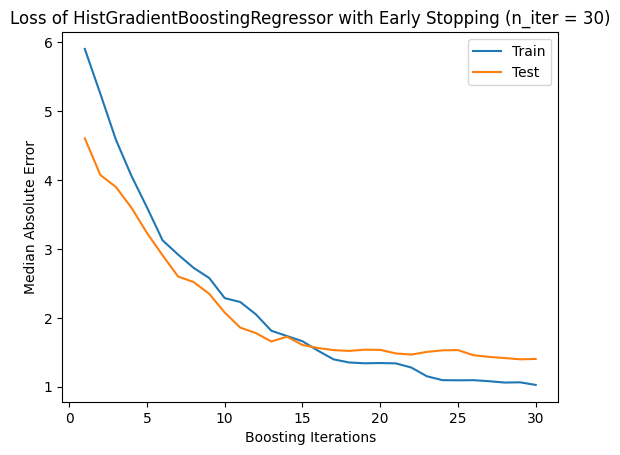

In [13]:
# plot errors with the optimal number of iterations
n_iter_stopped = search.best_estimator_.n_iter_ # obtain n_iter from early stopping implementation
n_iter_range = range(1, n_iter_stopped + 1) # use as explicit x-axis values to accommodate all error iterations
plt.plot(n_iter_range, train_errors, label="Train")
plt.plot(n_iter_range, test_errors, label="Test")

regressor_name = pipeline["estimator"].__class__.__name__
scoring_name = "Median Absolute Error"
plt.title(f"Loss of {regressor_name} with Early Stopping (n_iter = {n_iter_stopped})")
plt.xlabel("Boosting Iterations")
plt.ylabel(scoring_name)
plt.legend()
plt.show()

*Early stopping is a technique in Gradient Boosting to find the optimal number of iterations required to build a model that generalizes well, with its steps as follows:*
1. *A portion of the dataset is set aside as an internal validation set (specified using `validation_fraction`) to assess the model’s performance during training.*
2. *As the model is iteratively built with additional stages (trees), its performance on the validation set is monitored as a function of the number of steps.*
3. *Early stopping becomes effective when the model’s performance on the validation set plateaus or worsens (within deviations specified by `tol`) over a certain number of consecutive stages (specified by `n_iter_no_change`).*
4. *This signals that the model has reached a point where further iterations may lead to overfitting, and it is time to stop.*

* *Aforementioned parameters are automatically specified by scikit-learn and used in this section for efficiency purposes.*
* *The lines appear jagged, likely because the median absolute error is used to evaluate the loss: the median of the losses can remain unchanged and then jump suddenly when predictions cross the middle-ranked errors.*

Initially, early stopping is applied on `Train` set (blue line) to find the optimal `n_iter`, in which the model's error apparently plateaus after `30` iterations.
* With the same number of `n_iter`, staged prediction is implemented on `Test` set (green line).
* The gap between both lines is relatively low (`~0.5`), which indicates that model is **learning well and generalizing reasonably**.

#### Learning Curve

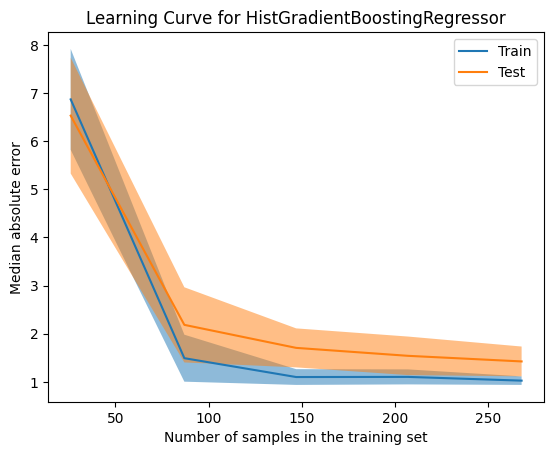

In [14]:
# visualize learning curve of the best estimator fitted on train set
disp = LearningCurveDisplay.from_estimator(
    **params_cv,
    shuffle=True,
    random_state=rng,
    negate_score=True
)

plt.title(f"Learning Curve for {regressor_name}")
plt.show()

*[Learning curve](https://scikit-learn.org/stable/modules/learning_curve.html#learning-curve) shows the training and validation score of an estimator for varying numbers of training samples.*
* *It is a tool to find out how much benefit obtained from adding more training data, and whether the estimator suffers more from [bias or variance]((https://en.wikipedia.org/wiki/Bias%E2%80%93variance_tradeoff)) error.*
* *The curves are plotted from averages of cross-validation scores fitted on `X_train & y_train`:*
    * *Therefore, the `Test` label is actually the internal validation set from the training set, rather than the separate `Test` set used in this project (`X_test, y_test`).*
    * *And the variability is shown with the shaded areas that represent a standard deviation above and below the mean for all cross-validations.*
    * *`negate_score` parameter is set to `True` which corresponds with previous implementation in [Section 3: Evaluation Metrics](#evaluation-metrics)*.

The observed pattern can be interpreted as follows:
* With small training samples `<100`, both training and test errors are much higher and slightly more variable (a.k.a. *variance error*), which comes from insufficient data that underfits the model and making it *sensitive to limited data*.
* As the training set increases around `100` observations, the errors decrease steadily, implying that **generalization improves from adding more training data**.
* After roughly `150` training samples, both curves flatten and remain close to one another.
    * This convergence suggests that adding more samples or any additional trainings from Auto MPG dataset are unlikely to produce further reduction in error.
    * The plot also corresponds with previous early stopping visualization: the model needs more data to reduce error and improve prediction.

#### Prediction Error

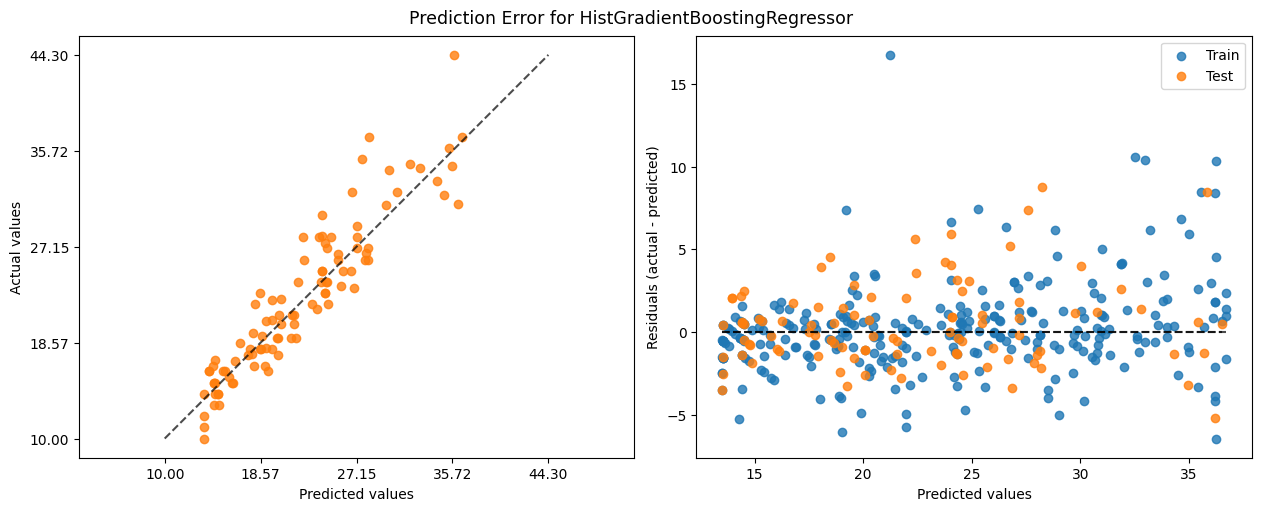

In [15]:
# plot prediction error given the true and predicted targets
width, height = 12.5, 5
fig = plt.figure(figsize=(width, height), layout="constrained")
mosaic = [["actual_vs_predicted", "residual_vs_predicted"]]
axes = fig.subplot_mosaic(mosaic)

color_spec = "C1" # use second-index default color spec for consistency purpose
PredictionErrorDisplay.from_predictions(
    y_test,
    y_pred,
    kind="actual_vs_predicted",
    ax=axes["actual_vs_predicted"],
    scatter_kwargs={"color": color_spec}
)

y_pred_train = pd.Series(
    search.best_estimator_.predict(X_train),
    index=pd.Series(X_train.index),
)
PredictionErrorDisplay.from_predictions(
    y_train,
    y_pred_train,
    kind="residual_vs_predicted",
    ax=axes["residual_vs_predicted"],
    scatter_kwargs={"label": "Train"},
)
PredictionErrorDisplay.from_predictions(
    y_test,
    y_pred,
    kind="residual_vs_predicted",
    ax=axes["residual_vs_predicted"],
    scatter_kwargs={"color": color_spec, "label": "Test"}
)

plt.suptitle(f"Prediction Error for {regressor_name}", fontsize=12.5)
plt.legend()
plt.show()

The figure above consists of two parts:

*1. [Prediction error](https://scikit-learn.org/stable/modules/model_evaluation.html#visual-evaluation-of-regression-models) plot on the left shows the actual $`y`$ targets from the dataset against the predicted $\hat{y}$ values generated by the model.*
* *This allows the user to see where the error is occurring, in what magnitude, and how much variance is present.*
* *The dotted lines in both plots indicate zero error, where the prediction exactly matches the observed value.*
* For a noise-free regression task aiming to predict the (conditional) expectation of $y$, a perfect regression model would display data points on the diagonal defined by predicted values equal to actual values.
    * In a more realistic setting with irreducible noise, that is, when not all variations of $y$ can be explained by features in $X$, the best model would lead to a cloud of points densely arranged around the diagonal, as seen in the figure above with blue data points around the black linear best fit.
    * This plot is also a visual representation of the test scores shown in [Section 3: Evaluation Metrics](#evaluation-metrics): the absolute midpoint of the vertical distance from each point to the dashed line $y = x$ is the median absolute error `mae` value of approximately `1.40`.

*2. The residuals-versus-fits plot on the right visualizes the residuals (i.e., the difference between the actual and predicted values) against the predicted values.*
* *The plot is particularly useful for investigating the behavior of a particular residual or a group of observations.*
* In a similar fashion to the previous plot, residuals should deviate from zero randomly rather than systematically for a well-fitting model. Thus, their distribution should be symmetric around zero, implying that their midpoint value should be zero. Residuals should also be close to zero themselves, indicating low variability.
    * Generally, residuals from both `Train & Test` sets form a random cloud around the dashed horizontal line with no particular structure observed, suggesting that the model is **not strongly biased** in one particular direction and shows **no obvious sign of major misspecification**.
    * However, at approximately $\hat{y} = 25$, the residuals begin to increase and making a notable funnel-shaped pattern from previous predicted values, reflecting **increasing variability of residuals** for increasing fitted values.
    * Additionally, it can also be seen from the previous prediction error plot that for actual `mpg` values above `35.72`, the predicted values berada cukup jauh dari ideal, perfect prediction of dashed diagonal value; possibly comes from inadequate data provided on this particular range of values.

### Model Deployment

*Model deployment involves placing a machine learning model into a production/real-world environment. Moving a model from development into production makes it available to end users to generate predictions on live data and benefit from its insights.*

#### Feature Scope

In [16]:
# obtain transformed train features
X_train_transformed = pd.DataFrame(dataset["train"][0]).copy()

# enable minimum-maximum calculation on feature with categorical data type
category_columns = X_train_transformed.select_dtypes("category").columns.item()
X_train_transformed[category_columns] = X_train_transformed[category_columns].cat.as_ordered()

# display inspection summary
data_inspect(X_train_transformed)

,dtype,sample,min,max,duplicated,missing
displacement,float64,"[97.0, 151.0, 140.0, 351.0, 79.0, 120.0, 429.0...",71.0,455.0,0,0
cylinders,int64,"[4, 8, 6]",4.0,8.0,0,0
horsepower,float64,"[88.0, 90.0, 92.0, 153.0, 149.0, 67.0, 75.0, 9...",46.0,230.0,0,2
weight,int64,"[2130, 2556, 2865, 4129, 4335, 2000, 2265, 250...",1649.0,5140.0,0,0
acceleration,float64,"[14.5, 13.2, 16.4, 13.0, 16.0, 18.2, 10.0, 14....",8.0,24.8,0,0
model_year,int64,"[71, 79, 82, 72, 77, 74, 70, 78, 76, 73, 75, 8...",70.0,82.0,0,0
origin,category,"[3, 1, 2] Categories (3, int64): [1 < 2 < 3]",1.0,3.0,0,0


*This section defines the boundaries, types, and quantity of input variables (features) used to train the model. Clear scoping prevents model drift, biased outputs, and failed real-world deployments.*

From the table above, scope of the features used to build the trained estimator is displayed:
* It covers each feature’s `dtype`, `sample` illustrating its unique values, and the available range (from `min` to `max`).
* Results of this inspection will be used to constrain inputs entered into model implementation, as described in the next section.

#### Model Persistence

In [17]:
# persist model and export transformed train features
model_dir = NOTEBOOK_DIR.parent / "model"
model_dir.mkdir(exist_ok=True)
with open(model_dir / "model.pkl", "wb") as model: # use write mode to binary file instead of default text mode
    pickle.dump(search.best_estimator_, model)

data_dir = NOTEBOOK_DIR.parent / "data"
data_dir.mkdir(exist_ok=True)
data_vars = [data_cleaned, X_train_transformed]
data_paths = [data_dir / "data_cleaned.csv", data_dir / "X_train_transformed.csv"]
for data_var, data_path in zip(data_vars, data_paths):
    pd.DataFrame(data_var).to_csv(data_path)

*After training a model, it is desirable to have a way to persist the model for future use without having to retrain.*
* *Based on the use case, there are a few [different ways](https://scikit-learn.org/stable/model_persistence.html) to persist a scikit-learn model with diagnostics to choose which one suits best.*
* For this project, `pickle` was chosen primarily because it is part of the Python Standard Library and can natively serialize and deserialize Python objects, while avoiding edge cases where the Scikit-learn model is unsupported by other persistence methods.

`model.pkl`, along with `X_train_transformed`, will be used to deploy the machine learning system.
* Different deployment methods exist depending on the applications and use cases for the model, such as real-time, batch, streaming, and edge deployment.
* For this system, a simple approach is preferred via [Streamlit](https://streamlit.io/) to turn the system into web services in which can be found in the `app` directory of this project.

<style>
  .back-to-top {
    display: flex;
    justify-content: center
  }

  .back-to-top a {
    padding: 10px;
    background-color: blue;
    color: white;
    text-decoration: none
  }

  .back-to-top a:hover {
    background-color: darkblue
  }
</style>

<div class="back-to-top">
  <a href="#top">Back to Top</a>
</div>